# LLM Evaluation Framework: Dietary Supplement Statements

This script provides a complete framework for evaluating multiple Large Language Models (LLMs) on dietary supplement-related statements using a 5-point Likert scale.

## Project Origin

- Statements were drafted and categorized in **Google Sheets**
- Finalized into a structured **JSON file** with metadata: audience, bias type, and human ratings

## Key Features

- Supports 10+ LLMs (OpenAI, Claude, Gemini, Mistral, DeepSeek, LLaMA, )
- Evaluates LLM alignment with consumer and expert responses
- Automated analysis includes:
  - Mean Absolute Difference (MAD)
  - Pearson Correlation
  - Subgroup comparisons by audience/bias
- Visualization-ready and Colab-compatible

## Workflow

1. **Setup**
   - Install packages, set API keys, mount Google Drive

2. **Query Models**
   - Run prompts across models
   - Responses saved incrementally in JSON

3. **Analyze Results**
   - Compute MAD and correlation
   - Generate plots and export CSV summaries

## Data Structure

Each JSON entry includes:
- `statement_id`: (e.g., "1.2.15" = Consumer.Negative.Statement15)
- `text`: Statement text
- `category`: Audience and bias type
- `user_response`: Ground truth (consumer or expert)
- `ai_response`: Model outputs by name

## Outputs

- `results.json`: Raw model responses
- `results_table.csv`: Analysis summary
- Visual comparison charts for model performance

> Requires API keys for each LLM provider used.

<!-- # **1.SETUP Install libraries -->
# **1. Environment Setup**

## 1.1. Install Required Libraries

In [ ]:
%pip install -q mistralai
%pip install -q anthropic
%pip install -q openai
%pip install -q llamaapi
%pip install -q torch
%pip install -q bitsandbytes
%pip install -q transformers accelerate
%pip install -q huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 301.5/301.5 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.0/264.0 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 64.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 45.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 88.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 1.2. Import Libraries

In [ ]:
import os
import sys
import io
import json
import time
import requests
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from collections import defaultdict
from matplotlib.colors import ListedColormap
import gspread
from google.colab import auth, userdata, drive
from google.auth import default
from googleapiclient.discovery import build
warnings.filterwarnings("ignore")
mpl.rcParams['text.usetex'] = False

from huggingface_hub import InferenceClient
from huggingface_hub import create_inference_endpoint
from huggingface_hub import hf_hub_download
import google.generativeai as genai
import openai
import anthropic
from llamaapi import LlamaAPI
from mistralai import Mistral
# from transformers import AutoTokenizer, AutoModelForCausalLM
# import torch, gc


drive.mount('/content/drive/', force_remount=True)

OUTPUT_DIR='/content/drive/MyDrive/Project_Results_LLM'
!ls '/content/drive/MyDrive/Project_Results_LLM'

!/usr/local/cuda/bin/nvcc --version
!nvidia-smi

Mounted at /content/drive/
final_full_results.csv	results.json  statements.json
nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Thu_Jun__6_02:18:23_PDT_2024
Cuda compilation tools, release 12.5, V12.5.82
Build cuda_12.5.r12.5/compiler.34385749_0
/bin/bash: line 1: nvidia-smi: command not found


## 1.3. Handle Import and Fetch Statements

In [6]:
auth.authenticate_user()
creds, _ = default()

gc = gspread.authorize(creds)
sheet2cat = {0: 1,1: 1,2: 2,3: 2}
sheet2type = {0: 1,1: 2,2: 1,3: 2}
statements = []
for w in range(4):
  worksheet = gc.open_by_key('1tivhIdpqu3ymvaFrheHg5cCR744BhRfPJ7ujSS4eZQA').get_worksheet(w)
  sheet_statements = worksheet.range('B3:B102')
  references = worksheet.range('C3:C102')
  user_answers = worksheet.range('D3:D102')

  for i in range(len(sheet_statements)):
    statements.append({
        'id': f"{sheet2cat[w]}.{sheet2type[w]}.{i+1}",
        'statement': sheet_statements[i].value,
        'reference_url': references[i].value,
        'user_answer': user_answers[i].value
    })
with open(f'{OUTPUT_DIR}/statements.json', 'w') as file:
  json.dump(statements, file, indent=4)

def load_statements_from_json(filename="statements.json"):
    path = f'{OUTPUT_DIR}/{filename}'
    with open(path, "r") as file:
        return json.load(file)

<!-- # **2. API Key Configuration** -->
# **2. API Configuration**

## 2.1. Set API Keys

In [ ]:
OPENAI_API_KEY = userdata.get('OPENAI_API_KEY')
ANTHROPIC_API_KEY = userdata.get('ANTHROPIC_API_KEY')
GOOGLE_API_KEY = userdata.get('GOOGLE_API_KEY')
DEEPSEEK_API_KEY = userdata.get('DEEPSEEK_API_KEY')
MISTRAL_API_KEY = userdata.get('MISTRAL_API_KEY')
LLAMA_API_KEY = userdata.get('LLAMA_API_KEY')
HUGGINGFACE_API_KEY = userdata.get ('HUGGINGFACE_API_KEY')

openai.api_key = OPENAI_API_KEY

anthropic_client = anthropic.Anthropic(api_key=ANTHROPIC_API_KEY)

genai.configure(api_key=GOOGLE_API_KEY)
gemini_model = genai.GenerativeModel("gemini-2.0-flash")

llama_client = LlamaAPI(LLAMA_API_KEY)

deepseek_client = openai.OpenAI(api_key=DEEPSEEK_API_KEY, base_url="https://api.deepseek.com")

mistral_client = Mistral(api_key=MISTRAL_API_KEY)

<!-- # 3. **Ask LLMs** -->
# **3. Querying Language Models**

<!-- ## 2.1. Prompt utils -->
## 3.1. LLM Query Functions

In [7]:
def query_openai_35_turbo(question):
    response = openai.chat.completions.create(
        model="gpt-3.5-turbo",
        messages=[{"role": "system", "content": "Answer concisely."},
                  {"role": "user", "content": question}]
    )
    return response.choices[0].message.content

def query_openai_o1_mini(question):
    response = openai.chat.completions.create(
        model="o1-mini",
        messages=[{"role": "user", "content": question}]
    )
    return response.choices[0].message.content

def query_google_gemini(question):
    config = genai.GenerationConfig(temperature=TEMP, max_output_tokens=10)
    response = gemini_model.generate_content(question, generation_config=config)
    return response.text.strip()


def query_anthropic_claude(question):
    message = anthropic_client.messages.create(
      model="claude-3-7-sonnet-20250219",
      max_tokens=10,
      messages=[{"role": "user", "content": question}],
    )
    return message.content[0].text

def query_llama33(question):
    api_request_json = {
        "model": "llama3.3-70b",
        "messages": [
            {"role": "system", "content": "Answer briefly with a number from 1-5 only."},
            {"role": "user", "content": question}
        ],
        "max_tokens": 5
    }

    response = llama_client.run(api_request_json)
    response_json = response.json()

    return response_json['choices'][0]['message']['content'].strip()


def query_deepseek_r1(question):
    response = deepseek_client.chat.completions.create(
        model="deepseek-reasoner",
        messages=[{"role": "user", "content": question}],
    )
    return response.choices[0].message.content


def query_mistral_large(question):
  chat_response = mistral_client.chat.complete(
    model = "mistral-large-latest",
    messages = [{"role": "user", "content": question}],

  )
  return chat_response.choices[0].message.content

def query_mistral_saba(question):
  chat_response = mistral_client.chat.complete(
    model = "mistral-saba-latest",
    messages = [{"role": "user","content": question}],

  )
  return chat_response.choices[0].message.content


def query_local_falcon3(prompt):
  inputs = tokenizer(prompt, return_tensors="pt").to("cuda")
  outputs = model.generate(**inputs, max_new_tokens=64)
  decoded = tokenizer.decode(outputs[0])

  if "<|assistant|>" not in decoded or "<|endoftext|>" not in decoded:
      print(f"Unexpected Falcon output:\n{decoded}\n")
      return "No response"

  decoded = decoded.split('<|assistant|>')[1].split('<|endoftext|>')[0].strip()
  return decoded


def query_local_exaone_deep(prompt):
  messages = [{"role": "user", "content": prompt}]
  input_ids = tokenizer.apply_chat_template(
      messages,
      tokenize=True,
      add_generation_prompt=True,
      return_tensors="pt"
  )
  output = model.generate(
        input_ids.to("cuda"),
        eos_token_id=tokenizer.eos_token_id,
        max_new_tokens=32768,
        do_sample=True,
        temperature=0.6,
        top_p=0.95,
    )
  decoded = tokenizer.decode(output[0])
  print(decoded)

  decoded = decoded.split('</thought>')[1].split('[|endofturn|]')[0].strip()
  return decoded

## 3.2. Query Execution

### 3.2.0. Main Module

In [8]:
prompt_template = '''
For the following statement please answer in five-level Likert Scale.
Statement: {}

Options:
1. Strongly disagree
2. Disagree
3. Undecided / Neutral
4. Agree
5. Strongly agree

Output must be short and only a number between 1 and 5.
No explanation is required.

Example output: 1
Example output: 2
Example output: 3
Example output: 4
Example output: 5
'''

def ask_llm(llm, query_func):
  statements = load_statements_from_json()
  results = load_results_from_json()
  wait_time = 10
  print(f'========= Start {llm} ========')
  i = 0
  while i < len(statements):
    id, statement = statements[i]['id'], statements[i]['statement']
    if llm not in results:
      results[llm] = {}

    if id in results[llm]:
      print(f'Skipping {id} as it is already answered by {llm}')
      i += 1
      continue
    prompt = prompt_template.format(statement)
    try:
      print(f'Asking: {id}')
      answer = query_func(prompt)
      print(f'Answer: {answer}')
      results[llm][id] = answer
      save_results_to_json(results)
      print('-----------------------------')
      time.sleep(2)
      i += 1
    except Exception as e:
      if '429' in str(e):
        print(f'Rate limit exceeded. Will retry in {wait_time} seconds...')
      else:
        print(e)
      time.sleep(wait_time)

  print(f'========= End {llm} ========', end='\n\n')

# for llm, func in llm_func.items():
  # ask_llm(llm, func)

### 3.2.1. OpenAI 3.5 Turbo

In [ ]:
ask_llm('OpenAI 3.5 Turbo', query_openai_35_turbo)

### 3.2.2. OpenAi o1 Mini

In [ ]:
ask_llm('OpenAI o1 Mini', query_openai_o1_mini)

### 3.2.3. Anthropic Claude 3.7

In [ ]:
ask_llm('Anthropic Claude 3.7', query_anthropic_claude)

### 3.2.4. Meta Llama 3.3 70B

In [ ]:
ask_llm('Meta Llama 3.3 70B', query_llama33)

### 3.2.5. Deepseek R1

In [ ]:
ask_llm('Deepseek R1', query_deepseek_r1)

### 3.2.6. Google Gemini 2.0 Flash

In [ ]:
ask_llm('Google Gemini 2.0 Flash', query_google_gemini)

### 3.2.7. Mistral Large

In [ ]:
ask_llm('Mistral Large', query_mistral_large)

### 3.2.8. Mistral Saba

In [ ]:
ask_llm('Mistral Saba', query_mistral_saba)

### 3.2.9. LG ExaOne DEEP 7.8B

In [ ]:
for name in ("model", "tokenizer"):
    try: del globals()[name]
    except: pass
torch.cuda.empty_cache(); gc.collect()

exaone_id = "LGAI-EXAONE/EXAONE-Deep-7.8B"
tokenizer = AutoTokenizer.from_pretrained(exaone_id)
model     = AutoModelForCausalLM.from_pretrained(
    exaone_id, device_map="auto", torch_dtype=torch.bfloat16
)
ask_llm('LG ExaOne Deep 7B', query_local_exaone_deep)

### 3.2.10. Falcon3 10B

In [ ]:
for name in ("model", "tokenizer"):
    try: del globals()[name]
    except: pass
torch.cuda.empty_cache(); gc.collect()

falcon_id = "tiiuae/Falcon3-10B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(falcon_id)
model     = AutoModelForCausalLM.from_pretrained(
    falcon_id, device_map="auto", torch_dtype=torch.bfloat16
)
ask_llm('Falcon3 10B', query_local_falcon3)

<!-- # **4. Saving and Loading Results** -->
# **4. Result Management**

## 4. Save Model Responses

In [9]:
def save_results_to_json(results, filename="results.json"):
    path = f'{OUTPUT_DIR}/{filename}'
    with open(path, "w") as file:
        json.dump(results, file, indent=4)

def load_results_from_json(filename="results.json"):
    path = f'{OUTPUT_DIR}/{filename}'
    if not os.path.exists(path):
        return {}
    with open(path, "r") as file:
        return json.load(file)

def load_user_answers_from_json(filename="statements.json"):
    statements = load_statements_from_json()
    result = {statement['id']:statement['user_answer'] for statement in statements}
    return result

# **5. Results Analysis Table**

In [ ]:
def calculate_stats(series_llm, series_user):
    diff = series_llm - series_user
    return {
        'Mean Abs Diff': diff.abs().mean(),
        'Median Diff': diff.median(),
        'Standard Deviation': diff.std(),
        'Min Diff': diff.min(),
        'Max Diff': diff.max(),
        'Pearson Corr': series_llm.corr(series_user, method='pearson')
    }

def load_responses_as_dataframe():
    llm_answers = load_results_from_json()
    user_answers = load_user_answers_from_json()

    df_responses = pd.DataFrame(llm_answers)
    df_responses.insert(0, 'User', user_answers.values())
    df_responses = df_responses.apply(pd.to_numeric)
    return df_responses

def collect_llm_statistics(df_responses, llm_list):
    stats_records = []

    df_consumer = df_responses[df_responses.index.str.startswith('1.')]
    df_professional = df_responses[df_responses.index.str.startswith('2.')]

    df_consumer_pos = df_consumer[df_consumer.index.str.split('.').str[1] == '1']
    df_consumer_neg = df_consumer[df_consumer.index.str.split('.').str[1] == '2']
    df_prof_pos = df_professional[df_professional.index.str.split('.').str[1] == '1']
    df_prof_neg = df_professional[df_professional.index.str.split('.').str[1] == '2']

    df_all_pos = pd.concat([df_consumer_pos, df_prof_pos])
    df_all_neg = pd.concat([df_consumer_neg, df_prof_neg])

    data_slices = [
        ("Overall", df_responses),
        ("Overall Positive", df_all_pos),
        ("Overall Negative", df_all_neg),
        ("Consumer Overall", df_consumer),
        ("Consumer Positive", df_consumer_pos),
        ("Consumer Negative", df_consumer_neg),
        ("Professional Overall", df_professional),
        ("Professional Positive", df_prof_pos),
        ("Professional Negative", df_prof_neg)
    ]

    for llm in llm_list:
        if llm not in df_responses.columns:
            continue
        for category_name, subset in data_slices:
            stats = calculate_stats(subset[llm], subset['User'])
            stats_records.append({
                'LLM': llm,
                'Category': category_name,
                **stats
            })

    return pd.DataFrame(stats_records)

df_responses = load_responses_as_dataframe()

llm_names = [
    'OpenAI 3.5 Turbo',
    'OpenAI o1 Mini',
    'Anthropic Claude 3.7',
    'Meta Llama 3.3 70B',
    'Deepseek R1',
    'Google Gemini 2.0 Flash',
    'Mistral Large',
    'Mistral Saba',
    'Falcon3 10B',
    'LG ExaOne Deep 7B'
]

stats_df = collect_llm_statistics(df_responses, llm_names)

stats_df_display = stats_df.round(3)
stats_df_display.index += 1

try:
    from IPython.display import display
    display(stats_df_display)
except ImportError:
    pass
# stats_df_display.to_csv('/content/drive/MyDrive/results_table.csv')

# **6. Data Visualization**

### 6.1.1 Mean Absolute Differences Bar Chart

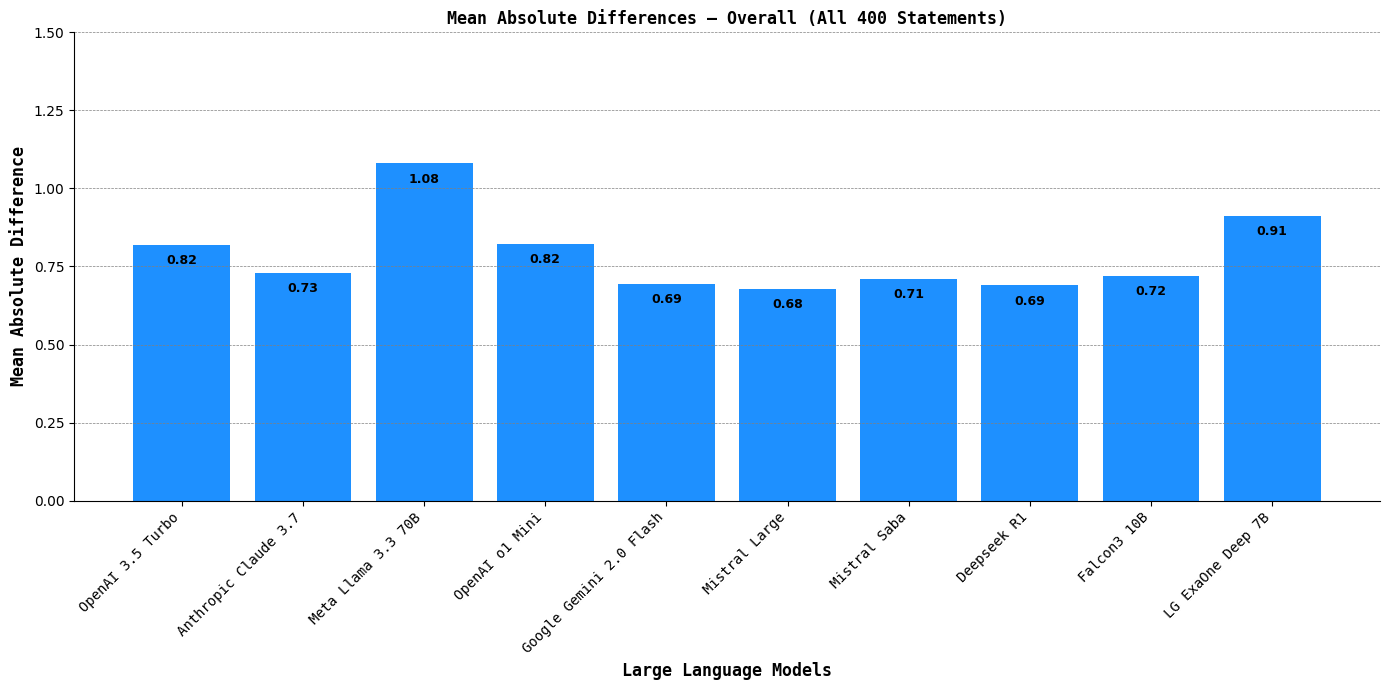

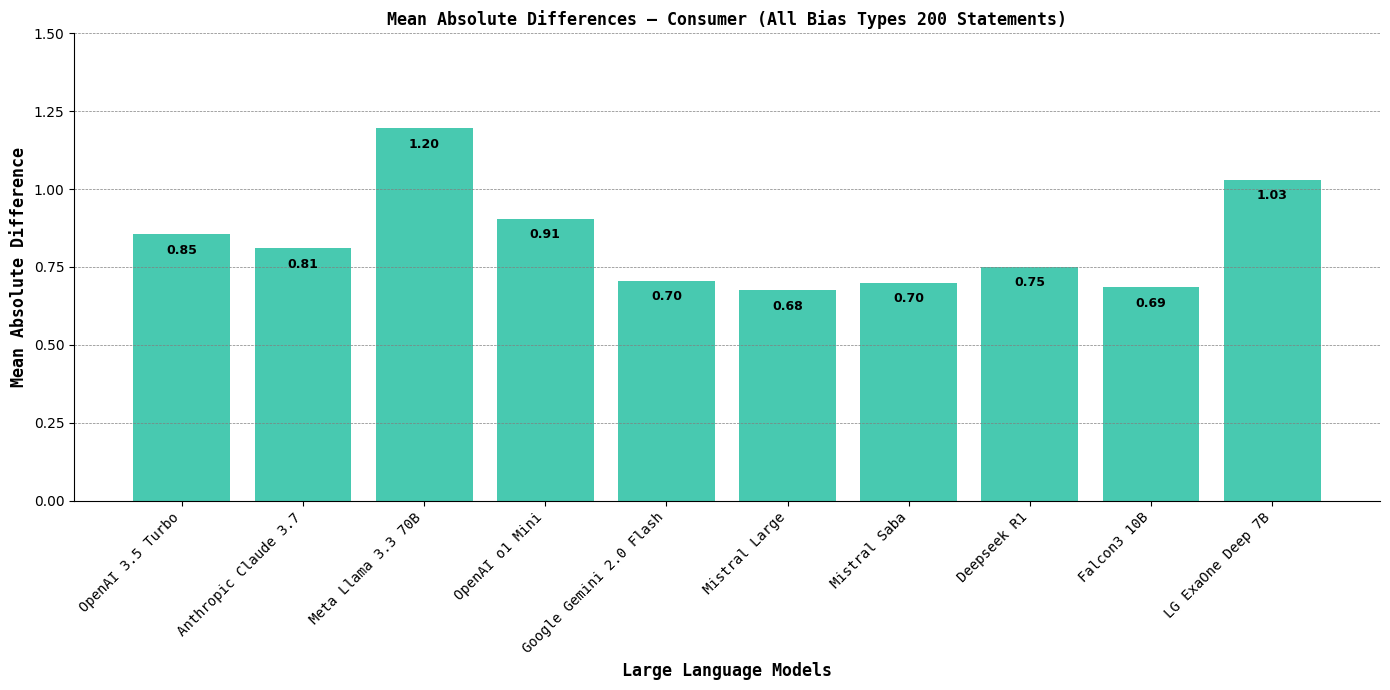

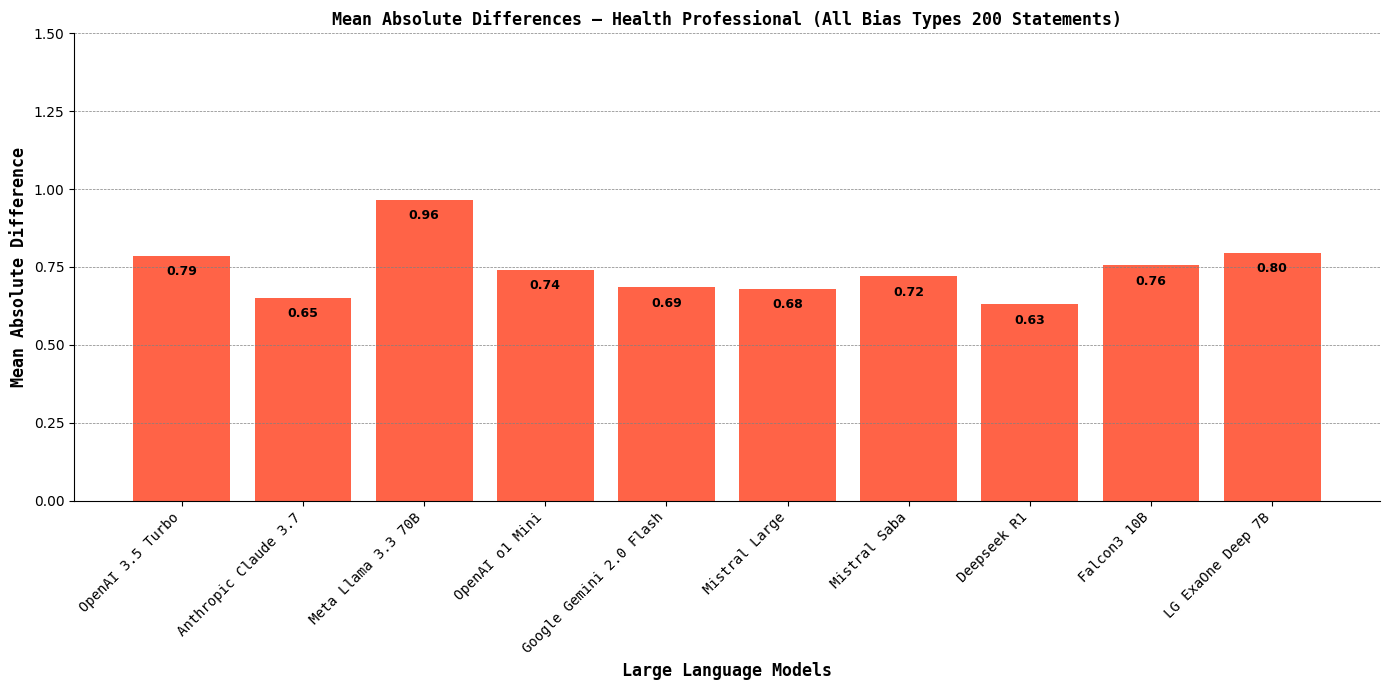

In [18]:
def compute_mad_overall_view(df_responses: pd.DataFrame) -> pd.DataFrame:
    metrics = defaultdict(dict)
    for llm in df_responses.columns:
        if llm == "User":
            continue

        diff = df_responses[llm] - df_responses["User"]
        metrics[llm]["Mean Absolute Differences – Overall (All 400 Statements)"] = diff.abs().mean()

        consumer = df_responses[df_responses.index.str.startswith("1.")]
        consumer_diff = consumer[llm] - consumer["User"]
        metrics[llm]["Mean Absolute Differences – Consumer (All Bias Types 200 Statements)"] = consumer_diff.abs().mean()

        professional = df_responses[df_responses.index.str.startswith("2.")]
        professional_diff = professional[llm] - professional["User"]
        metrics[llm]["Mean Absolute Differences – Health Professional (All Bias Types 200 Statements)"] = professional_diff.abs().mean()

    return pd.DataFrame(metrics).T

df_mad_overall = compute_mad_overall_view(df_responses)

mad_df = df_mad_overall[[col for col in df_mad_overall.columns if "Absolute Difference" in col]]
models = mad_df.index.tolist()

colors = ["#1E90FF", "#48C9B0", "#FF6347"]

for i, column in enumerate(mad_df.columns):
    values = mad_df[column].loc[models].values

    fig, ax = plt.subplots(figsize=(14, 7))
    bars = ax.bar(models, values, color=colors[i % len(colors)])

    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    y_ticks = np.arange(0.0, 1.51, 0.25)
    ax.set_yticks(y_ticks)
    ax.set_ylim(0.0, 1.5)
    ax.grid(axis="y", linestyle="--", linewidth=0.5, color="gray")

    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h - 0.03,
            f"{h:.2f}",
            ha='center',
            va='top',
            color='black',
            fontweight='bold',
            fontsize=9
        )

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    ax.set_ylabel("Mean Absolute Difference", fontsize=12, fontweight='bold', fontname='DejaVu Sans Mono')
    ax.set_xlabel("Large Language Models", fontsize=12, fontweight='bold', fontname='DejaVu Sans Mono')
    ax.set_title(column, fontsize=12, fontweight='bold', fontname='DejaVu Sans Mono')
    plt.xticks(rotation=45, ha="right", fontsize=10, fontname='DejaVu Sans Mono')

    plt.tight_layout()
    # plt.savefig(f"{column}.png", dpi=300, bbox_inches='tight')
    plt.show()

### 6.1.2. Mean Absolute Difference by Category

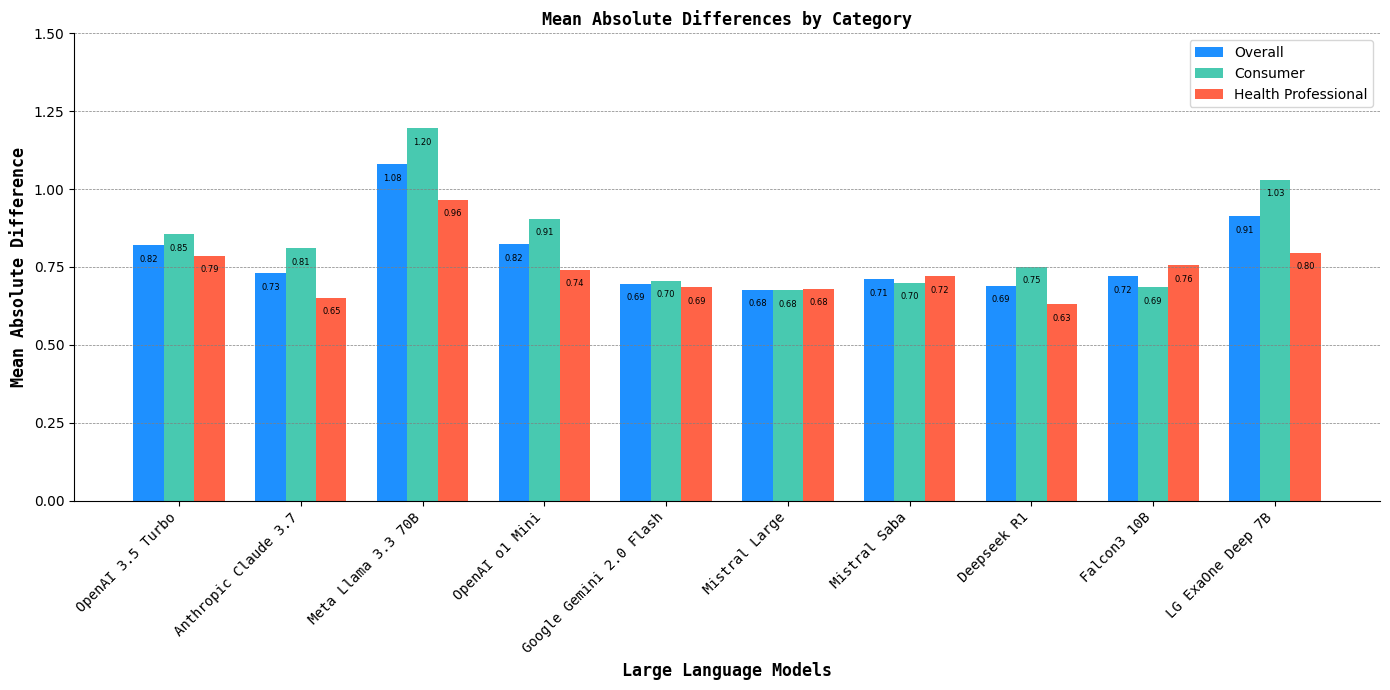

In [19]:
def compute_llm_abs_diffs(df_responses: pd.DataFrame) -> pd.DataFrame:
    metrics = defaultdict(dict)
    for llm in df_responses.columns:
        if llm == "User":
            continue

        diff = df_responses[llm] - df_responses["User"]
        metrics[llm]["Overall Mean Absolute Difference"] = diff.abs().mean()

        consumer = df_responses[df_responses.index.str.startswith("1.")]
        consumer_diff = consumer[llm] - consumer["User"]
        metrics[llm]["Consumer Mean Absolute Difference"] = consumer_diff.abs().mean()

        professional = df_responses[df_responses.index.str.startswith("2.")]
        professional_diff = professional[llm] - professional["User"]
        metrics[llm]["Health Professional Mean Absolute Difference"] = professional_diff.abs().mean()

    return pd.DataFrame(metrics).T

df_metrics = compute_llm_abs_diffs(df_responses)

mad_df = df_metrics[
    [col for col in df_metrics.columns if "Absolute Difference" in col]
]

models = mad_df.index.tolist()
overall = mad_df["Overall Mean Absolute Difference"].values
consumer = mad_df["Consumer Mean Absolute Difference"].values
health = mad_df["Health Professional Mean Absolute Difference"].values

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 7))

color_overall = "#1E90FF"
color_consumer = "#48C9B0"
color_health = "#FF6347"

bars_overall = ax.bar(x - width, overall, width, label="Overall", color=color_overall)
bars_consumer = ax.bar(x, consumer, width, label="Consumer", color=color_consumer)
bars_health = ax.bar(x + width, health, width, label="Health Professional", color=color_health)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

y_ticks = np.arange(0.0, 1.51, 0.25)
ax.set_yticks(y_ticks)
ax.set_ylim(0.0, 1.5)
ax.grid(axis="y", linestyle="--", linewidth=0.5, color="gray")

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax.set_ylabel("Mean Absolute Difference", fontsize=12, fontweight='bold', fontname='DejaVu Sans Mono')
ax.set_xlabel("Large Language Models", fontsize=12, fontweight='bold', fontname='DejaVu Sans Mono')
ax.set_title("Mean Absolute Differences by Category", fontsize=12, fontweight='bold', fontname='DejaVu Sans Mono')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha="right", fontsize=10, fontname='DejaVu Sans Mono')
ax.legend()

for bar_group in [bars_overall, bars_consumer, bars_health]:
    for bar in bar_group:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h - 0.03,
            f"{h:.2f}",
            ha="center",
            va="top",
            color="black",
            fontsize=6
        )

plt.tight_layout()
# plt.savefig("Mean_Absolute_Differences_by_Category.png", dpi=300, bbox_inches="tight")
plt.show()

### 6.1.3 Mean Absolute Difference by Bias Type

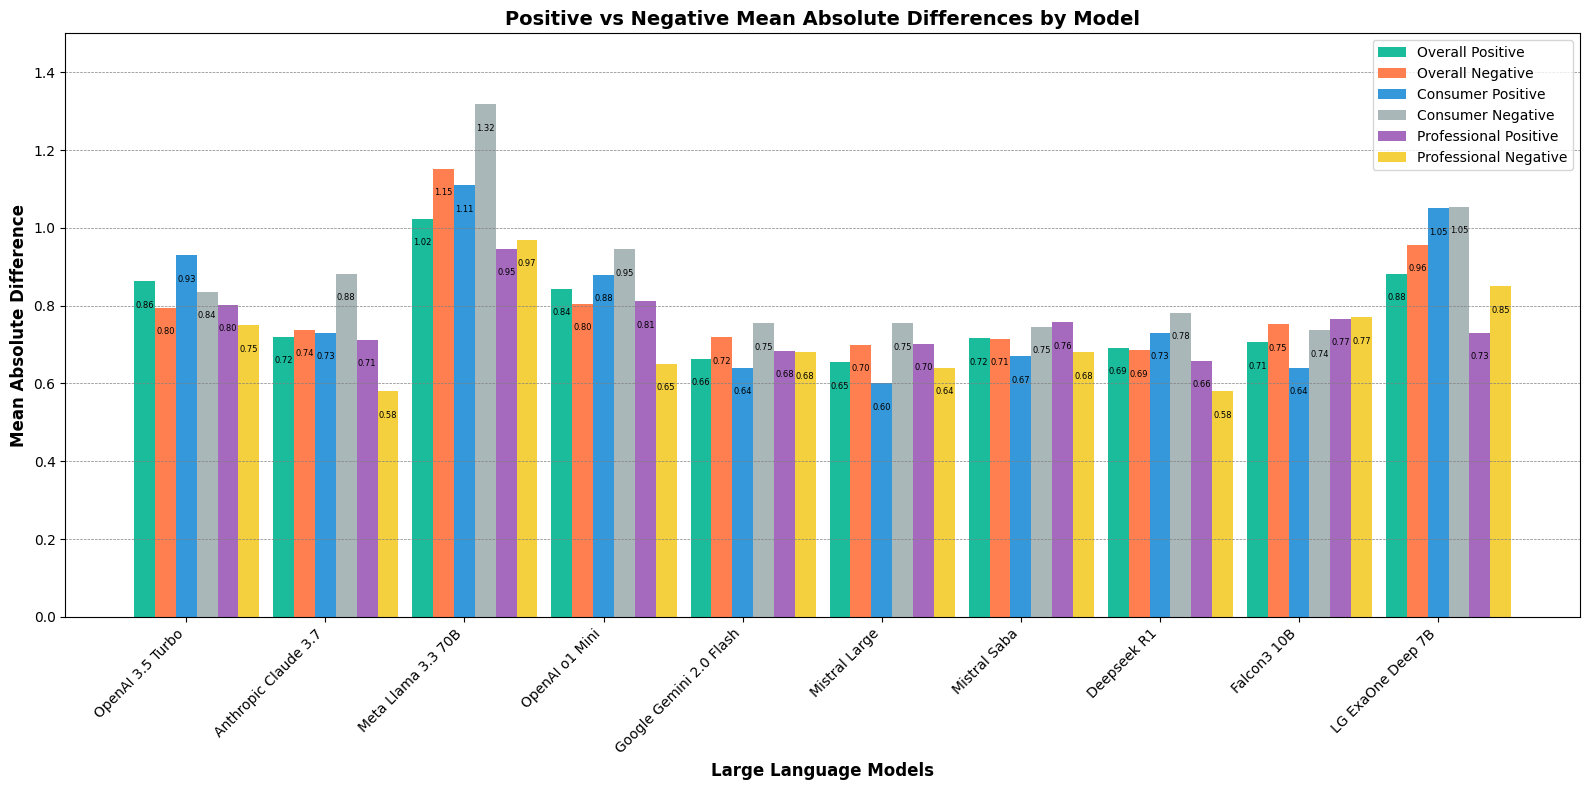

In [21]:
def compute_llm_abs_diffs_with_bias(df_responses: pd.DataFrame) -> pd.DataFrame:
    metrics = defaultdict(dict)

    for llm in df_responses.columns:
        if llm == "User":
            continue

        diff = df_responses[llm] - df_responses["User"]
        metrics[llm]["Overall MAD"] = diff.abs().mean()

        consumer = df_responses[df_responses.index.str.startswith("1.")]
        professional = df_responses[df_responses.index.str.startswith("2.")]

        consumer_positive = consumer[consumer.index.str.contains("1.1.")]
        consumer_negative = consumer[consumer.index.str.contains("1.2.")]
        professional_positive = professional[professional.index.str.contains("2.1.")]
        professional_negative = professional[professional.index.str.contains("2.2.")]

        consumer_diff = consumer[llm] - consumer["User"]
        metrics[llm]["Consumer MAD"] = consumer_diff.abs().mean()

        metrics[llm]["Consumer Positive MAD"] = (consumer_positive[llm] - consumer_positive["User"]).abs().mean()
        metrics[llm]["Consumer Negative MAD"] = (consumer_negative[llm] - consumer_negative["User"]).abs().mean()

        professional_diff = professional[llm] - professional["User"]
        metrics[llm]["Health Professional MAD"] = professional_diff.abs().mean()

        metrics[llm]["Professional Positive MAD"] = (professional_positive[llm] - professional_positive["User"]).abs().mean()
        metrics[llm]["Professional Negative MAD"] = (professional_negative[llm] - professional_negative["User"]).abs().mean()

        all_positive = pd.concat([consumer_positive, professional_positive])
        all_negative = pd.concat([consumer_negative, professional_negative])

        metrics[llm]["Overall Positive MAD"] = (all_positive[llm] - all_positive["User"]).abs().mean()
        metrics[llm]["Overall Negative MAD"] = (all_negative[llm] - all_negative["User"]).abs().mean()

    return pd.DataFrame(metrics).T

df_metrics = compute_llm_abs_diffs_with_bias(df_responses)

models = df_metrics.index.tolist()
overall_positive = df_metrics["Overall Positive MAD"].values
overall_negative = df_metrics["Overall Negative MAD"].values
consumer_positive = df_metrics["Consumer Positive MAD"].values
consumer_negative = df_metrics["Consumer Negative MAD"].values
professional_positive = df_metrics["Professional Positive MAD"].values
professional_negative = df_metrics["Professional Negative MAD"].values

x = np.arange(len(models))
width = 0.15

fig, ax = plt.subplots(figsize=(16, 8))

bar1 = ax.bar(x - 2*width, overall_positive, width, label="Overall Positive", color="#1ABC9C")
bar2 = ax.bar(x - width, overall_negative, width, label="Overall Negative", color="#FF7F50")
bar3 = ax.bar(x, consumer_positive, width, label="Consumer Positive", color="#3498DB")
bar4 = ax.bar(x + width, consumer_negative, width, label="Consumer Negative", color="#AAB7B8")
bar5 = ax.bar(x + 2*width, professional_positive, width, label="Professional Positive", color="#A569BD")
bar6 = ax.bar(x + 3*width, professional_negative, width, label="Professional Negative", color="#F4D03F")

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.set_ylabel("Mean Absolute Difference", fontsize=12, fontweight="bold")
ax.set_xlabel("Large Language Models", fontsize=12, fontweight="bold")
ax.set_title("Positive vs Negative Mean Absolute Differences by Model", fontsize=14, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha="right", fontsize=10)

ax.grid(axis="y", linestyle="--", linewidth=0.5, color="gray")
ax.set_ylim(0.0, 1.5)

ax.legend()

for bar_group in [bar1, bar2, bar3, bar4, bar5, bar6]:
    for bar in bar_group:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height - 0.05,
            f"{height:.2f}",
            ha="center",
            va="top",
            fontsize=6,
            color="black"
        )
plt.tight_layout()
# plt.savefig("Positive_vs_Negative_MAD_by_Model.png", dpi=300, bbox_inches="tight")
plt.show()

### 6.2.1 Pearson Correlation Bar Chart

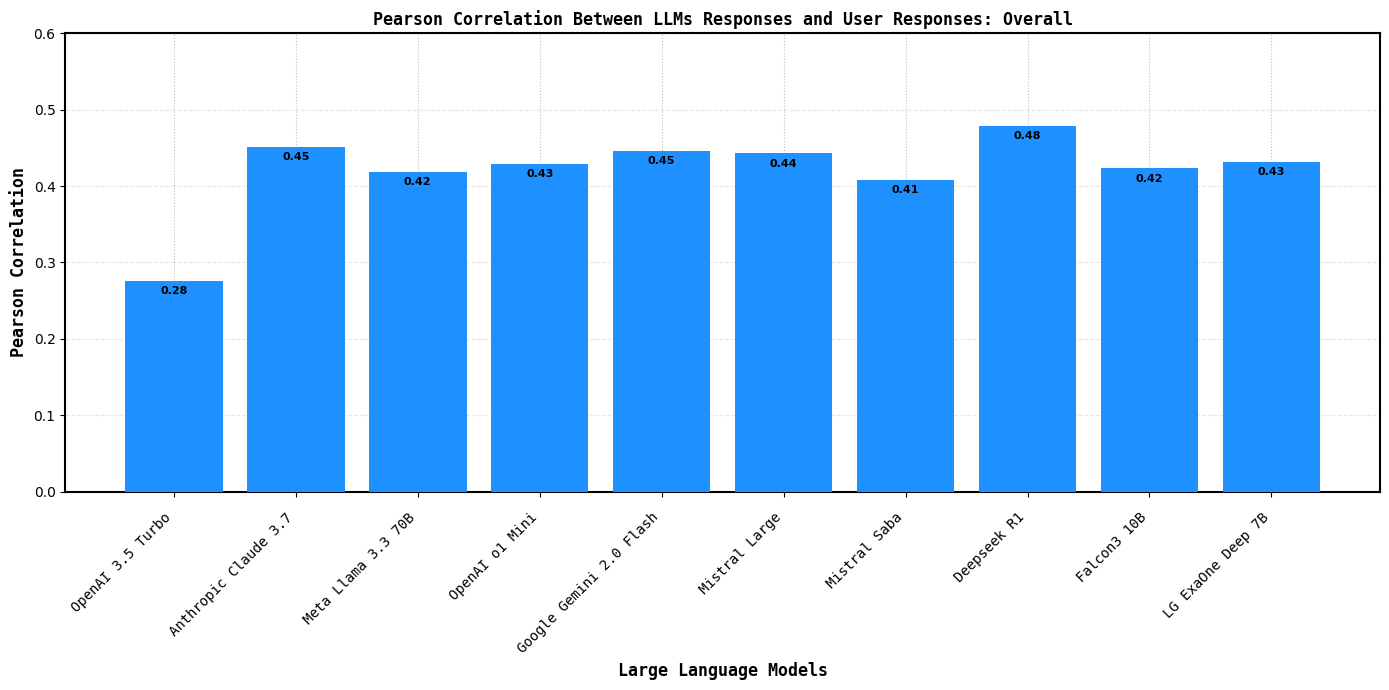

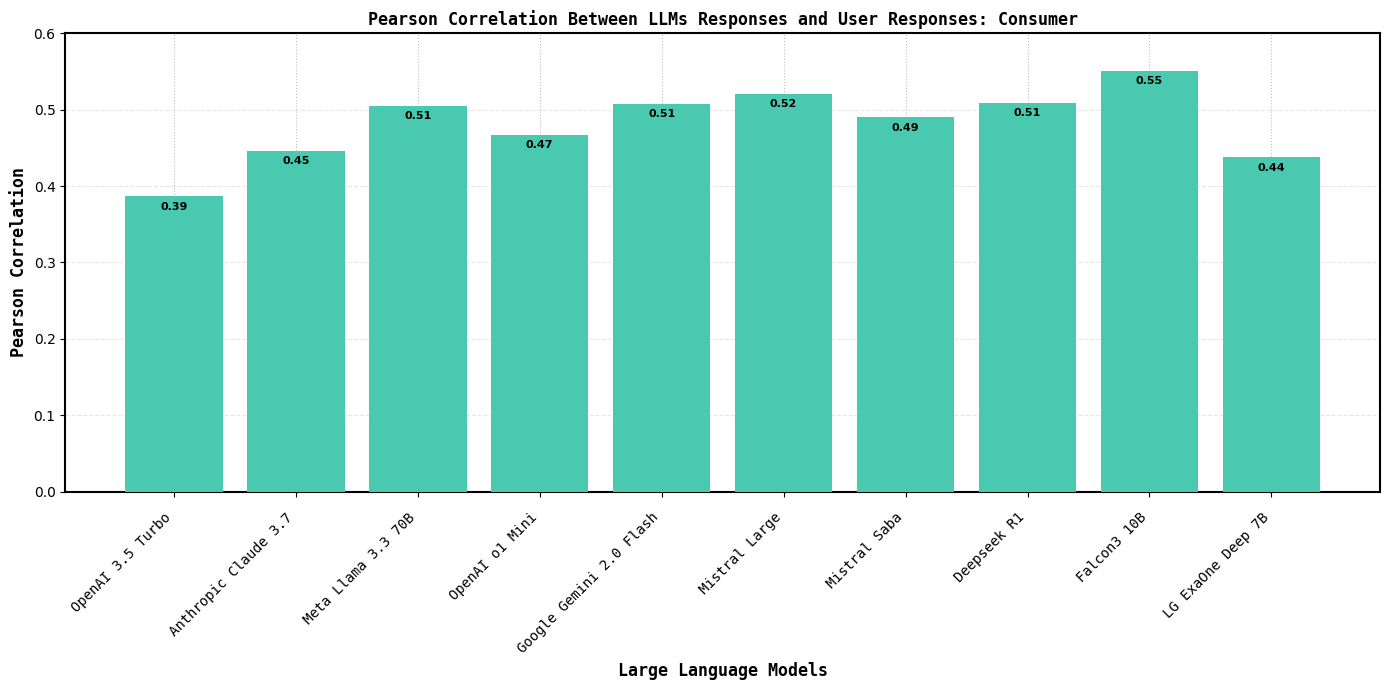

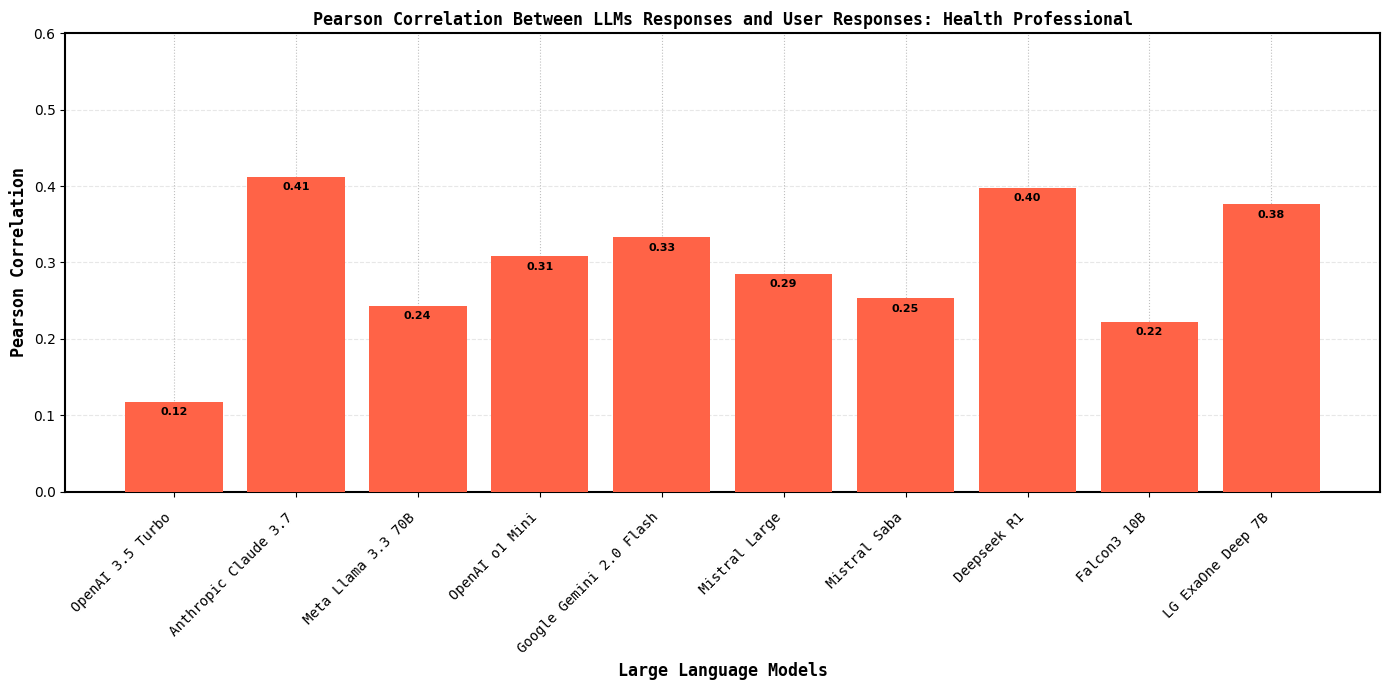

In [24]:
df_corr = pd.DataFrame()

for llm in df_responses.columns:
    if llm == "User":
        continue

    corr_overall = df_responses[llm].corr(df_responses["User"], method="pearson")
    consumer = df_responses[df_responses.index.str.startswith("1.")]
    consumer_corr = consumer[llm].corr(consumer["User"], method="pearson")
    professional = df_responses[df_responses.index.str.startswith("2.")]
    professional_corr = professional[llm].corr(professional["User"], method="pearson")

    df_corr.loc[llm, "Overall"] = corr_overall
    df_corr.loc[llm, "Consumer"] = consumer_corr
    df_corr.loc[llm, "Health Professional"] = professional_corr

models = df_corr.index.tolist()
categories = df_corr.columns.tolist()

color_mapping = {
    "Overall": "#1E90FF",
    "Consumer": "#48C9B0",
    "Health Professional": "#FF6347"
}

for category in categories:
    values = df_corr[category]
    fig, ax = plt.subplots(figsize=(14, 7))

    bar_color = color_mapping.get(category, "#3498DB")

    bars = ax.bar(models, values, color=bar_color, zorder=3)

    for i in range(len(models)):
        ax.axvline(x=i, color='gray', linestyle=':', linewidth=0.8, alpha=0.5, zorder=1)

    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height - 0.02,
            f"{height:.2f}",
            ha='center',
            va='bottom',
            fontsize=8,
            fontweight='bold',
            color='black'
        )

    ax.set_ylabel("Pearson Correlation", fontsize=12, fontweight='bold', fontname='DejaVu Sans Mono')
    ax.set_xlabel("Large Language Models", fontsize=12, fontweight='bold', fontname='DejaVu Sans Mono')
    ax.set_title(f"Pearson Correlation Between LLMs Responses and User Responses: {category}",
                 fontsize=12, fontweight='bold', fontname='DejaVu Sans Mono')
    ax.set_xticks(range(len(models)))
    ax.tick_params(axis='x', pad=10)
    ax.set_xticklabels(models, rotation=45, ha='right', fontsize=10, fontname='DejaVu Sans Mono')

    ax.set_ylim(0.0, 0.6)

    ax.axhline(0, color='gray', linestyle='--', linewidth=1, zorder=2)
    ax.grid(True, axis='y', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')

    plt.tight_layout()
    # plt.savefig(f"Pearson_Correlation_{category.replace(' ', '_')}.png", dpi=300, bbox_inches='tight')
    plt.show()

### 6.2.2 Pearson Correlation By Category

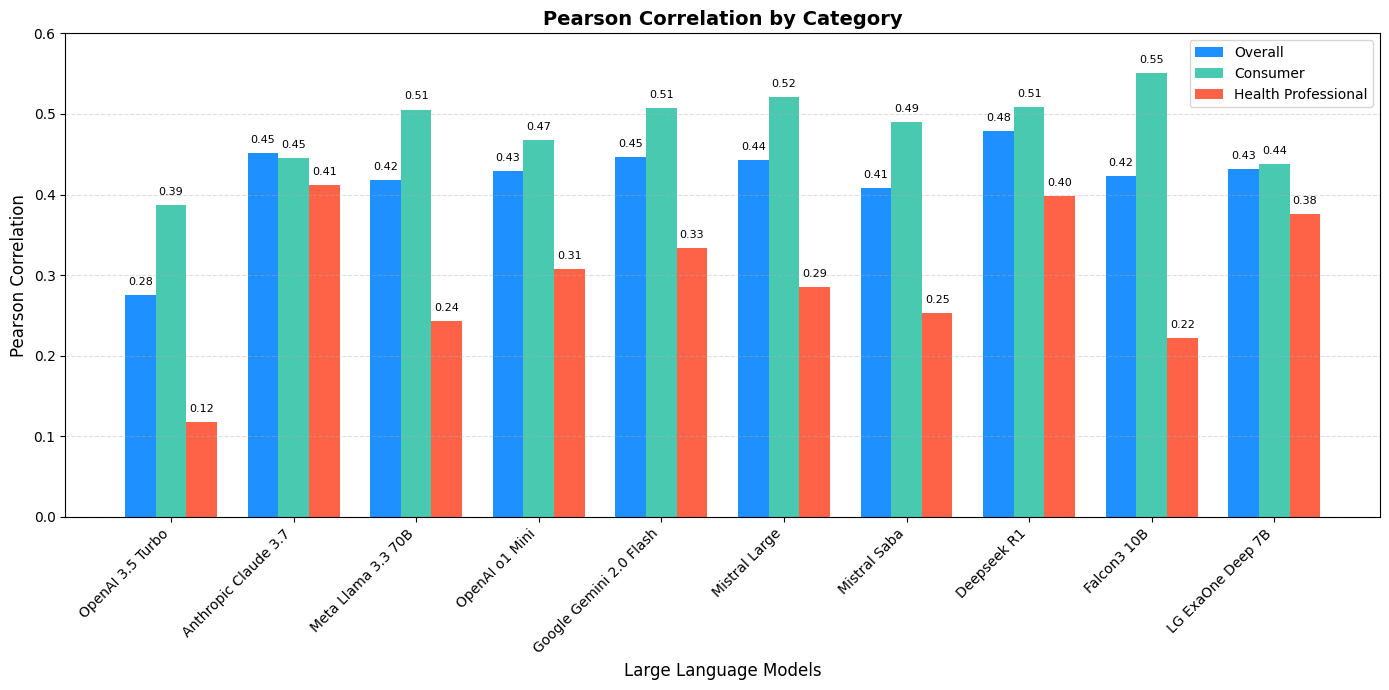

In [25]:
df_corr = pd.DataFrame()
for llm in df_responses.columns:
    if llm == "User":
        continue
    corr_overall = df_responses[llm].corr(df_responses["User"], method="pearson")

    consumer = df_responses[df_responses.index.str.startswith("1.")]
    consumer_corr = consumer[llm].corr(consumer["User"], method="pearson")
    professional = df_responses[df_responses.index.str.startswith("2.")]
    professional_corr = professional[llm].corr(professional["User"], method="pearson")

    df_corr.loc[llm, "Overall"] = corr_overall
    df_corr.loc[llm, "Consumer"] = consumer_corr
    df_corr.loc[llm, "Health Professional"] = professional_corr

models = df_corr.index.tolist()
x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 7))

bars_overall = ax.bar(x - width, df_corr['Overall'], width, label='Overall', color="#1E90FF")
bars_consumer = ax.bar(x, df_corr['Consumer'], width, label='Consumer', color="#48C9B0")
bars_health = ax.bar(x + width, df_corr['Health Professional'], width, label='Health Professional', color="#FF6347")

ax.set_title("Pearson Correlation by Category", fontsize=14, fontweight='bold')
ax.set_ylabel("Pearson Correlation", fontsize=12)
ax.set_xlabel("Large Language Models", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right', fontsize=10)
ax.set_ylim(0.0, 0.6)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()

for bar_group in [bars_overall, bars_consumer, bars_health]:
    for bar in bar_group:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h + 0.01,
            f"{h:.2f}",
            ha='center',
            va='bottom',
            fontsize=8,
            color='black'
        )

plt.tight_layout()
# plt.savefig("Pearson_Correlation_Chart.png", dpi=300, bbox_inches='tight')
plt.show()

### 6.3. Scatter Plot of Pearson and MAD

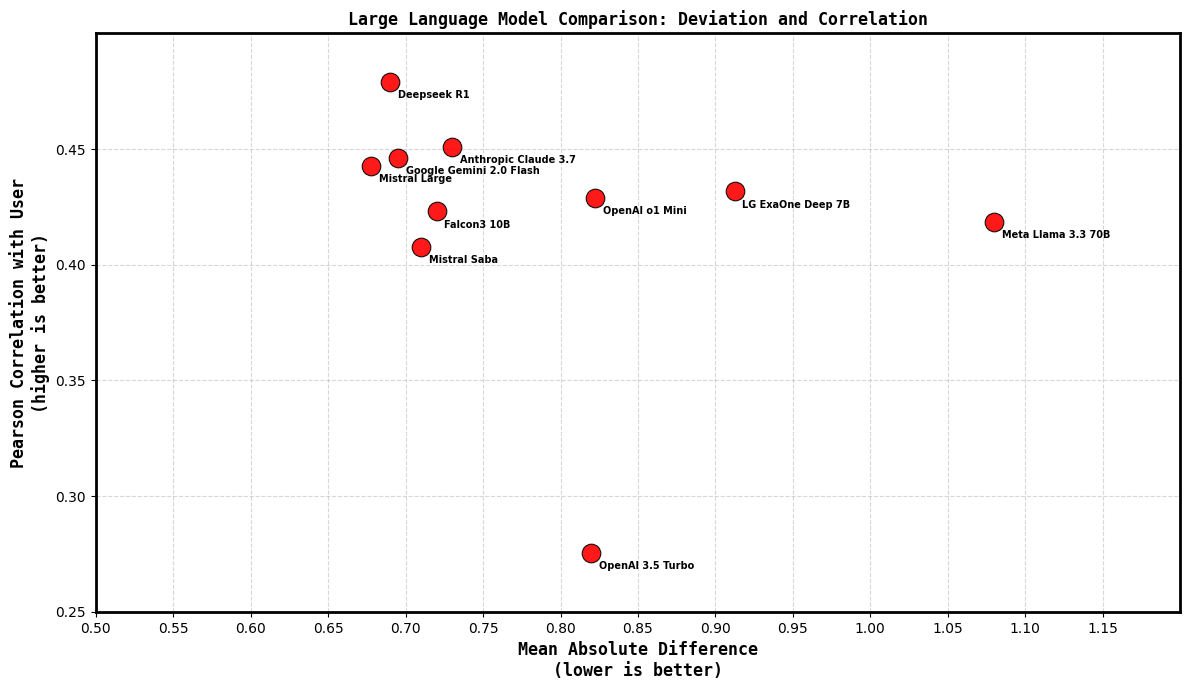

In [26]:
def compute_metrics_for_scatter(df_responses):
    data = []
    for llm in df_responses.columns:
        if llm == "User":
            continue
        diff = df_responses[llm] - df_responses["User"]
        mad = diff.abs().mean()
        pearson = df_responses[llm].corr(df_responses["User"], method="pearson")
        data.append((llm, mad, pearson))
    return pd.DataFrame(data, columns=["LLM", "MeanAbsDiff", "PearsonCorr"])

df_metrics = compute_metrics_for_scatter(df_responses)

fig, ax = plt.subplots(figsize=(12, 7))

for i, row in df_metrics.iterrows():
    ax.scatter(
        row["MeanAbsDiff"],
        row["PearsonCorr"],
        marker='o',
        s=180,
        color='red',
        edgecolor='black',
        linewidth=0.8,
        alpha=0.9,
        zorder=3
    )
    ax.text(
        row["MeanAbsDiff"] + 0.005,
        row["PearsonCorr"] - 0.008,
        row["LLM"],
        fontsize=7,
        weight='bold',
        ha='left',
        va='bottom'
    )

ax.axhline(0.15, linestyle='--', color='gray', linewidth=1, alpha=0.7, zorder=1)
ax.axhline(0.0, linestyle='--', color='gray', linewidth=1, alpha=0.7, zorder=1)

ax.set_title("Large Language Model Comparison: Deviation and Correlation",fontsize=12, fontweight='bold', fontname='DejaVu Sans Mono')
ax.set_xlabel("Mean Absolute Difference\n(lower is better)",fontsize=12, fontweight='bold', fontname='DejaVu Sans Mono')
ax.set_ylabel("Pearson Correlation with User\n(higher is better)",fontsize=12, fontweight='bold', fontname='DejaVu Sans Mono')

ax.grid(True, linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(True, linestyle='--', alpha=0.5)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(2.0)
    spine.set_color('black')

ax.set_yticks(np.arange(0.25, 0.5, 0.05))
ax.set_ylim(0.25, 0.5)

ax.set_xticks(np.arange(0.0, 1.2, 0.05))
ax.set_xlim(0.5, 1.2)

plt.tight_layout()
# plt.savefig("LLM_Scatter_Accuracy_vs_Correlation.png", dpi=600, bbox_inches='tight')
plt.show()